In [1]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("/content/play_tennis.csv")

In [4]:
df

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


In [7]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

In [8]:
le = {}
df_enc = df.copy()
for col in df_enc.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df_enc[col])
df_enc

,day,outlook,temp,humidity,wind,play
0,0,2,1,0,1,0
1,6,2,1,0,0,0
2,7,0,1,0,1,1
3,8,1,2,0,1,1
4,9,1,0,1,1,1
5,10,1,0,1,0,0
6,11,0,0,1,0,1
7,12,2,2,0,1,0
8,13,2,0,1,1,1
9,1,1,2,1,1,1


In [12]:
x = df_enc[['outlook', 'temp', 'humidity', 'wind']]
y = df_enc['play']
x

,outlook,temp,humidity,wind
0,2,1,0,1
1,2,1,0,0
2,0,1,0,1
3,1,2,0,1
4,1,0,1,1
5,1,0,1,0
6,0,0,1,0
7,2,2,0,1
8,2,0,1,1
9,1,2,1,1


In [10]:
model = CategoricalNB()
model.fit(x,y)

CategoricalNB()

In [11]:
test = [['D1',	'Sunny',	'Hot',	'High',	'Weak',	'No']]
test

[['D1', 'Sunny', 'Hot', 'High', 'Weak', 'No']]

In [21]:
print("\n---- Prediction ----------------------------------")
for t in test:
  row = [[
      le['outlook'].transform([t[1]])[0],
      le['temp'].transform([t[2]])[0],
      le['humidity'].transform([t[3]])[0],
      le['wind'].transform([t[4]])[0]
  ]]
  pred = le['play'].inverse_transform(model.predict(row))[0]
  prob = model.predict_proba(row)[0]
  print(f"Input : outlook =({t[1]}) temp =({t[2]}) humidity =({t[3]}) wind =({t[4]})")
  print(f"Output: play =({pred})")
  print(f"Result : play -> {pred}")
  print(f"P(No) = {prob[0]:.4f}, P(Yes) = {prob[1]:.4f}")
  print("--------------------------------------------------")


---- Prediction ----------------------------------
Input : outlook =(Sunny) temp =(Hot) humidity =(High) wind =(Weak)
Output: play =(No)
Result : play -> No
P(No) = 0.6880, P(Yes) = 0.3120
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [19]:
from sklearn.metrics import accuracy_score

# Re-fit the model using the correct features (x, y)
model.fit(x, y)

y_pred = model.predict(x)
print(f"\n Training Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


 Training Accuracy: 92.86%


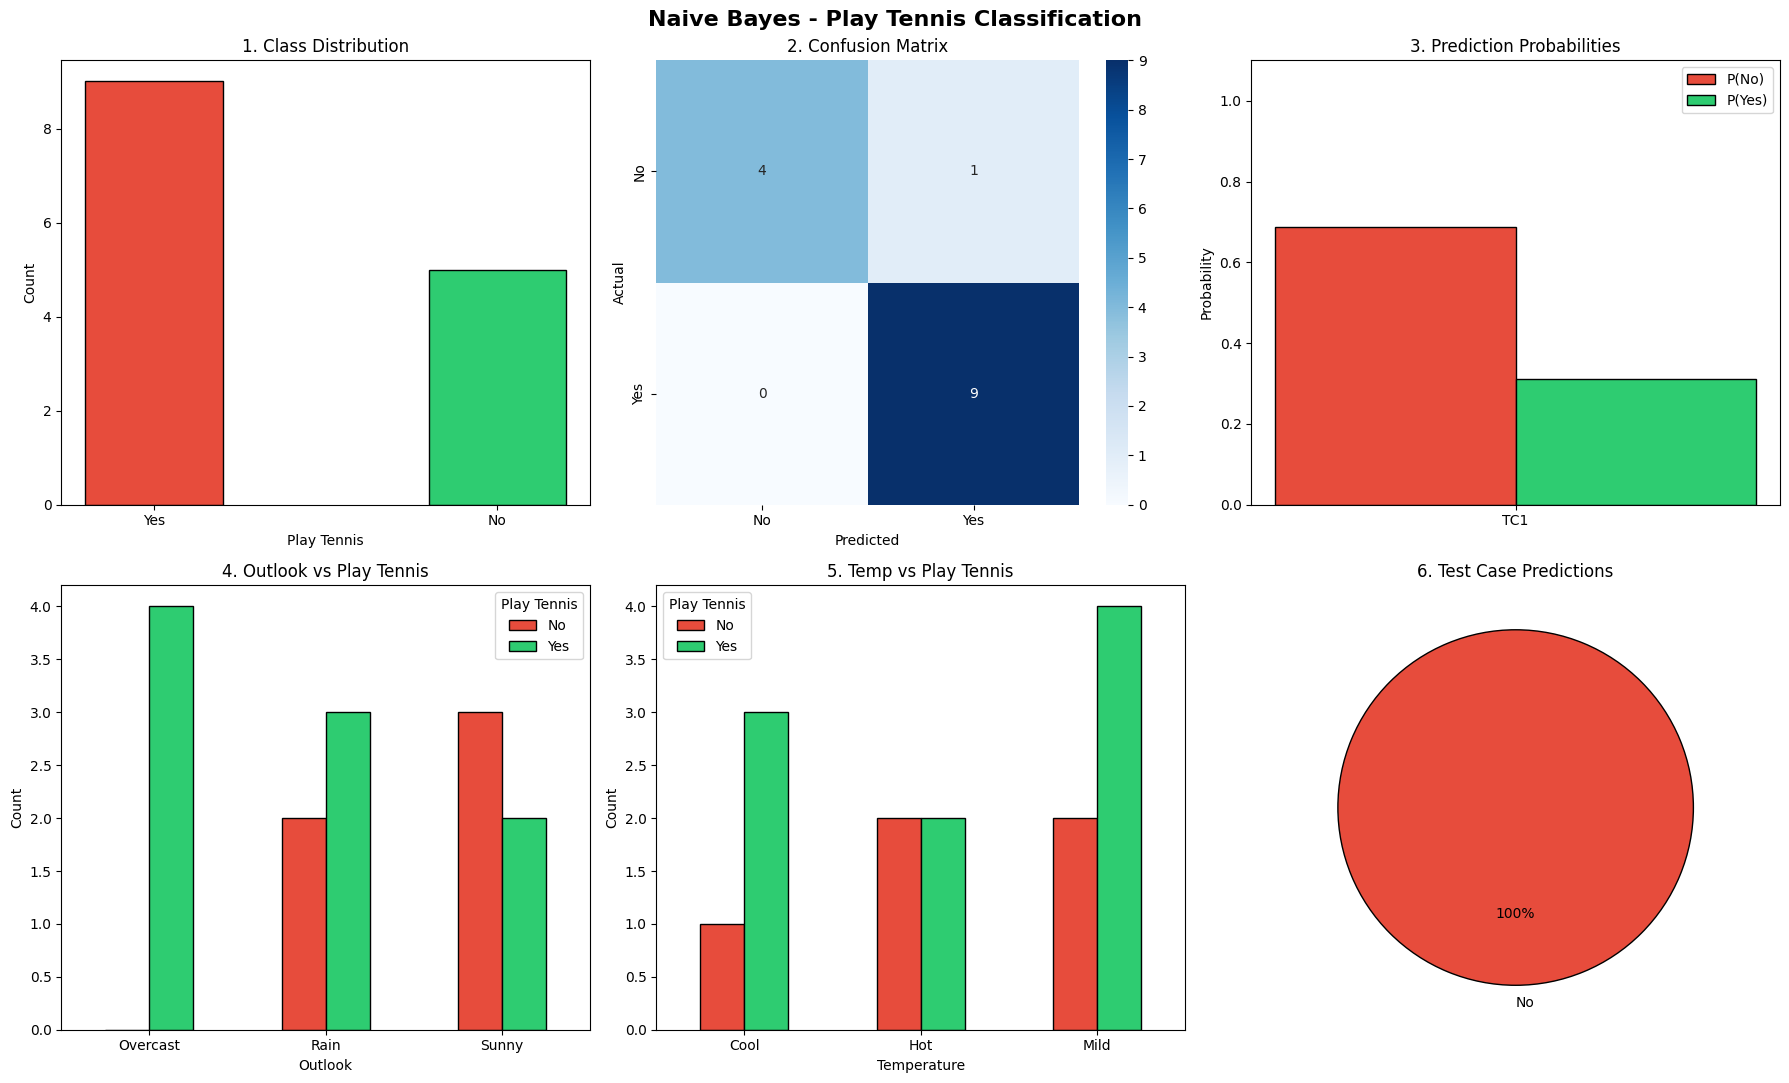

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Configure subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Play Tennis Classification", fontsize=16, fontweight='bold')

# 1. Class Distribution - Corrected column name from 'Buys_Computer' to 'play'
counts = df['play'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("Play Tennis")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=['No','Yes'], yticklabels=['No','Yes'], ax=axes[0, 1], fmt='d')
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# Define test cases for visualization
test_cases = ["TC1"]
probs_no = [prob[0]]
probs_yes = [prob[1]]

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_axis = np.arange(len(tc_labels))
w = 0.3
axes[0, 2].bar(x_axis - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_axis + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_xticks(x_axis)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].legend()

# 4. Outlook vs Play Tennis (Corrected from Age vs Buys Computer)
outlook_counts = df.groupby(['outlook', 'play']).size().unstack(fill_value=0)
outlook_counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0, ax=axes[1, 0])
axes[1, 0].set_title("4. Outlook vs Play Tennis")
axes[1, 0].set_xlabel("Outlook")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title='Play Tennis')

# 5. Temp vs Play Tennis (Corrected from Income vs Buys Computer)
temp_counts = df.groupby(['temp', 'play']).size().unstack(fill_value=0)
temp_counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0, ax=axes[1, 1])
axes[1, 1].set_title("5. Temp vs Play Tennis")
axes[1, 1].set_xlabel("Temperature")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title='Play Tennis')

# 6. Test Case Predictions
predictions = [pred]
pred_series = pd.Series(predictions)
pred_counts = pred_series.value_counts()
colors_pie = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_pie, autopct='%1.0f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()